# TriggerNet Level 1 — Notebook 03: Shrinking the Network (Pruning + QAT)

## Why We Compress Before Touching Hardware
Our Float32 baseline from Notebook 02 needs **~4.36 Million Bit-Operations (BOPs)** per jet and 32-bit floating-point multipliers. On an FPGA trigger chip, floating-point multipliers are enormous and slow.

We shrink the network using **two orthogonal hardware tricks**:

### Trick 1: Global L1 Magnitude Pruning (`50% → 75% → 80%` Sparsity)
- After training, many weights sit very close to `0.0` (e.g., `0.003`).
- We zero out the smallest `p%` of weights across the network using a binary mask, then **fine-tune** the surviving weights so they compensate for the deleted connections.
- **Why zeros are magic on an FPGA:** Unlike a CPU/GPU (where unstructured zeros often still run through dense matrix-multiply hardware), when `hls4ml` compiles a network into FPGA circuits, **any weight equal to `0` is completely deleted at compile time** (`0 × x = 0`). Deleting 75% of weights literally saves ~75% of the FPGA's **DSP multipliers**!

### Trick 2: Fixed-Point Quantization (`ap_fixed<W, I>`) via QAT
Instead of 32-bit IEEE floating-point numbers, FPGAs use **fixed-point binary numbers** written as `ap_fixed<W, I>`:
- `W` = total number of bits (e.g. `8`, `6`, or `4` bits).
- `I` = integer bits (including the sign bit).
- `F = W - I` = fractional bits, giving grid resolution `Δ = 2^(-F)`.
- Example: `ap_fixed<8, 2>` has 1 sign bit, 1 integer bit, and 6 fractional bits → range `[-2.0, +1.984375]` in tiny steps of `1/64 = 0.015625`!
- And after `ReLU`, activations are never negative (`x >= 0`), so we use **unsigned** `ap_ufixed<W, I>` and get **1 extra bit of fractional precision for free**!

#### PTQ vs. QAT (Crucial CERN Interview Question!)
- **Post-Training Quantization (PTQ):** Round the Float32 weights *after* training. Works decently at 8+ bits, but **collapses at 6-bit and 4-bit** because the network never learned to cope with rounding noise.
- **Quantization-Aware Training (QAT):** Insert the exact `ap_fixed<W, I>` rounding operation *inside the forward pass during training* using the **Straight-Through Estimator (STE)**:
  - Forward pass: uses rounded fixed-point numbers `q(w)`.
  - Backward pass: passes gradients straight through `∂q(w)/∂w ≈ 1` inside the clamp bounds.
  - Result: the network adapts its weights to land cleanly on the tiny 6-bit or 4-bit hardware grid!

### Hardware Cost Metric: Effective Bit-Operations (BOPs)
Following CERN/FastML literature (`Hawks et al., 2021`), we estimate hardware compute cost using:
`Effective BOPs = (Non-Zero Multiply-Accumulates) × weight_bits × activation_bits`

In [1]:
from pathlib import Path
import json
import sys
import copy
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.models import JetMLP, QuantizedJetMLP, QFixedLinear, load_float_weights_into_qat
from src.metrics import CLASS_NAMES, evaluate_jet_predictions, compute_model_hardware_stats

torch.manual_seed(42)
np.random.seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATA_PATH = PROJECT_ROOT / "data" / "hls4ml_lhc_jets_hlf.npz"
CKPT_DIR = PROJECT_ROOT / "checkpoints"
FIG_DIR = PROJECT_ROOT / "figures"
RES_DIR = PROJECT_ROOT / "results"

data = np.load(DATA_PATH, allow_pickle=True)
X_train, X_val, X_test = data["X_train"], data["X_val"], data["X_test"]
y_train, y_val, y_test = data["y_train"], data["y_val"], data["y_test"]

X_train_t, y_train_t = torch.from_numpy(X_train).to(device), torch.from_numpy(y_train).to(device)
X_val_t, y_val_t = torch.from_numpy(X_val).to(device), torch.from_numpy(y_val).to(device)
X_test_t = torch.from_numpy(X_test).to(device)


class FastTensorBatcher:
    """Vectorized mini-batch slicer (~40x faster than row-by-row DataLoader on CPU)."""

    def __init__(self, x: torch.Tensor, y: torch.Tensor | None, batch_size: int, shuffle: bool = False):
        self.x = x
        self.y = y
        self.batch_size = batch_size
        self.shuffle = shuffle

    def __iter__(self):
        n = len(self.x)
        if self.shuffle:
            idx = torch.randperm(n, device=self.x.device)
            for start in range(0, n, self.batch_size):
                sl = idx[start : start + self.batch_size]
                yield self.x[sl], (self.y[sl] if self.y is not None else None)
        else:
            for start in range(0, n, self.batch_size):
                yield self.x[start : start + self.batch_size], (
                    self.y[start : start + self.batch_size] if self.y is not None else None
                )


train_loader = FastTensorBatcher(X_train_t, y_train_t, batch_size=4096, shuffle=True)
val_loader = FastTensorBatcher(X_val_t, y_val_t, batch_size=16384, shuffle=False)
test_loader = FastTensorBatcher(X_test_t, None, batch_size=16384, shuffle=False)

# Load Float32 baseline from Notebook 02
float_model = JetMLP().to(device)
float_model.load_state_dict(torch.load(CKPT_DIR / "float32_baseline.pt", map_location=device, weights_only=True))
float_model.eval()
float_summary = json.loads((RES_DIR / "float32_metrics.json").read_text())
print(f"Loaded Float32 Baseline: Test Acc={float_summary['accuracy']*100:.2f}%, Macro AUC={float_summary['macro_auc']:.4f}, BOPs={float_summary['hardware']['effective_bops']:,}")

Loaded Float32 Baseline: Test Acc=76.71%, Macro AUC=0.9431, BOPs=4,358,144


In [2]:
def evaluate_model_on_loader(model: nn.Module, loader: DataLoader) -> tuple[np.ndarray, dict]:
    model.eval()
    probs_list = []
    with torch.no_grad():
        for xb, _ in loader:
            logits = model(xb.to(device))
            probs_list.append(torch.softmax(logits, dim=1).cpu().numpy())
    probs = np.concatenate(probs_list, axis=0)
    return probs, evaluate_jet_predictions(y_test, probs, CLASS_NAMES)


def run_ptq_only(
    base_float_model: JetMLP,
    weight_bits: int,
    weight_int_bits: int,
    act_bits: int,
    act_int_bits: int,
    sparsity: float = 0.0,
) -> tuple[QuantizedJetMLP, dict]:
    """Naive Post-Training Quantization (+ optional pruning) with ZERO fine-tuning."""
    q_model = QuantizedJetMLP(
        weight_bits=weight_bits,
        weight_int_bits=weight_int_bits,
        act_bits=act_bits,
        act_int_bits=act_int_bits,
    ).to(device)
    load_float_weights_into_qat(base_float_model, q_model)
    if sparsity > 0:
        q_model.apply_global_magnitude_pruning(sparsity)
    _, m = evaluate_model_on_loader(q_model, test_loader)
    return q_model, m


def train_qat_and_prune(
    base_float_model: JetMLP,
    weight_bits: int,
    weight_int_bits: int,
    act_bits: int,
    act_int_bits: int,
    target_sparsity: float = 0.0,
    epochs: int = 12,
    lr: float = 1.5e-3,
) -> tuple[QuantizedJetMLP, dict, dict]:
    """Warm-start from Float32, progressively prune to target_sparsity, and fine-tune with QAT."""
    q_model = QuantizedJetMLP(
        weight_bits=weight_bits,
        weight_int_bits=weight_int_bits,
        act_bits=act_bits,
        act_int_bits=act_int_bits,
    ).to(device)
    load_float_weights_into_qat(base_float_model, q_model)

    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(q_model.parameters(), lr=lr)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs, eta_min=1e-4)

    # Ramp sparsity gradually during the first half of epochs (gentle recovery!)
    prune_end_epoch = max(1, epochs // 2)
    best_val_loss = float("inf")
    best_state = copy.deepcopy(q_model.state_dict())

    for epoch in range(1, epochs + 1):
        if target_sparsity > 0.0 and epoch <= prune_end_epoch:
            frac = epoch / prune_end_epoch
            cur_sparsity = target_sparsity * (1.0 - (1.0 - frac) ** 3)  # cubic schedule (Zhu & Gupta)
            q_model.apply_global_magnitude_pruning(cur_sparsity)

        q_model.train()
        for xb, yb in train_loader:
            xb, yb = xb.to(device), yb.to(device)
            optimizer.zero_grad()
            loss = criterion(q_model(xb), yb)
            loss.backward()
            optimizer.step()
            # Keep pruned weights strictly zero after optimizer update
            if target_sparsity > 0.0:
                with torch.no_grad():
                    for mod in q_model.modules():
                        if isinstance(mod, QFixedLinear):
                            mod.weight.mul_(mod.weight_mask)

        scheduler.step()

        # Only track best checkpoint once target sparsity has been reached
        if epoch >= prune_end_epoch:
            q_model.eval()
            va_loss_sum, va_total = 0.0, 0
            with torch.no_grad():
                for xb, yb in val_loader:
                    xb, yb = xb.to(device), yb.to(device)
                    va_loss_sum += criterion(q_model(xb), yb).item() * len(yb)
                    va_total += len(yb)
            va_loss = va_loss_sum / va_total
            if va_loss < best_val_loss:
                best_val_loss = va_loss
                best_state = copy.deepcopy(q_model.state_dict())

    q_model.load_state_dict(best_state)
    exported = q_model.export_to_standard_sequential().to(device)
    hw = compute_model_hardware_stats(exported, weight_bits=weight_bits, act_bits=act_bits)
    _, test_metrics = evaluate_model_on_loader(q_model, test_loader)
    return q_model, test_metrics, hw

## 1. Experiment A — Why QAT Beats Naive Post-Training Quantization (PTQ)
Let's prove directly with numbers what happens when you naively round a Float32 network to `8-bit`, `6-bit`, and `4-bit` fixed-point (**PTQ**) vs. letting the network adapt via **QAT**. Watch how badly 4-bit PTQ collapses compared to 4-bit QAT!

In [3]:
ptq_vs_qat_rows = []
bit_configs = [
    # (weight_bits, weight_int_bits, act_bits, act_int_bits)
    (8, 2, 8, 3),
    (6, 2, 6, 3),
    (4, 2, 4, 3),
]

for wb, wi, ab, ai in bit_configs:
    _, m_ptq = run_ptq_only(float_model, wb, wi, ab, ai, sparsity=0.0)
    _, m_qat, _ = train_qat_and_prune(float_model, wb, wi, ab, ai, target_sparsity=0.0, epochs=10)
    ptq_vs_qat_rows.append({
        "Precision": f"W=ap_fixed<{wb},{wi}>, A=ap_ufixed<{ab},{ai}>",
        "PTQ Acc (%)": m_ptq["accuracy"] * 100,
        "QAT Acc (%)": m_qat["accuracy"] * 100,
        "PTQ AUC": m_ptq["macro_auc"],
        "QAT AUC": m_qat["macro_auc"],
        "QAT Gain (ΔAUC)": m_qat["macro_auc"] - m_ptq["macro_auc"],
    })

ptq_df = pd.DataFrame(ptq_vs_qat_rows)
print("PTQ (Zero Fine-Tuning) vs. QAT (Straight-Through Estimator):")
print(ptq_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

PTQ (Zero Fine-Tuning) vs. QAT (Straight-Through Estimator):
                        Precision  PTQ Acc (%)  QAT Acc (%)  PTQ AUC  QAT AUC  QAT Gain (ΔAUC)
W=ap_fixed<8,2>, A=ap_ufixed<8,3>      76.7000      76.7343   0.9428   0.9432           0.0004
W=ap_fixed<6,2>, A=ap_ufixed<6,3>      75.5530      76.4392   0.9384   0.9413           0.0029
W=ap_fixed<4,2>, A=ap_ufixed<4,3>      57.5247      74.4651   0.8784   0.9301           0.0518


## 2. Experiment B — Full Compression Sweep (Bit-Width × Pruning Sparsity)
Now we sweep across:
- **Float32 Pruned:** `50%`, `75%`, `80%` pruning (isolating the effect of pruning alone!)
- **QAT + Pruned:** `8-bit`, `6-bit`, and `4-bit` combined with `0%`, `50%`, `75%`, and `80%` global magnitude pruning!

We save the best compressed checkpoints to `checkpoints/` so **Notebook 04** can convert them straight into real C++ FPGA firmware via `hls4ml`.

In [4]:
sweep_specs = [
    # (tag, w_bits, w_int, a_bits, a_int, sparsity, epochs)
    ("FP32_p50", 32, 8, 32, 8, 0.50, 10),
    ("FP32_p75", 32, 8, 32, 8, 0.75, 10),
    ("FP32_p80", 32, 8, 32, 8, 0.80, 10),
    ("QAT_8b_p0", 8, 2, 8, 3, 0.00, 12),
    ("QAT_8b_p50", 8, 2, 8, 3, 0.50, 12),
    ("QAT_8b_p75", 8, 2, 8, 3, 0.75, 12),
    ("QAT_6b_p0", 6, 2, 6, 3, 0.00, 12),
    ("QAT_6b_p50", 6, 2, 6, 3, 0.50, 12),
    ("QAT_6b_p75", 6, 2, 6, 3, 0.75, 14),
    ("QAT_4b_p0", 4, 2, 4, 3, 0.00, 14),
    ("QAT_4b_p50", 4, 2, 4, 3, 0.50, 14),
    ("QAT_4b_p75", 4, 2, 4, 3, 0.75, 14),
]

sweep_results = [
    {
        "tag": "FP32_Baseline",
        "weight_bits": 32,
        "weight_int_bits": 8,
        "act_bits": 32,
        "act_int_bits": 8,
        "target_sparsity": 0.0,
        "actual_sparsity": float_summary["hardware"]["sparsity"],
        "nonzero_weights": float_summary["hardware"]["nonzero_weights"],
        "weight_kb": float_summary["hardware"]["weight_kb"],
        "effective_bops": float_summary["hardware"]["effective_bops"],
        "bop_reduction_pct": 0.0,
        "accuracy": float_summary["accuracy"],
        "macro_auc": float_summary["macro_auc"],
        "mean_rej_50": float_summary["mean_rej_50"],
        "mean_rej_80": float_summary["mean_rej_80"],
    }
]

base_bops = float_summary["hardware"]["effective_bops"]
saved_models = {}
t_start = time.perf_counter()

for tag, wb, wi, ab, ai, sp, ep in sweep_specs:
    if wb == 32:
        # Pure float pruning (no quantization noise)
        m_fp = copy.deepcopy(float_model).to(device)
        # Reuse QAT helper with 24-bit fixed point? Better: mask JetMLP directly for exact FP32!
        all_w = torch.cat([mod.weight.detach().abs().flatten() for mod in m_fp.modules() if isinstance(mod, nn.Linear)])
        k = int(round(sp * all_w.numel()))
        thr = torch.kthvalue(all_w, k).values.item()
        masks = {}
        with torch.no_grad():
            for name, mod in m_fp.named_modules():
                if isinstance(mod, nn.Linear):
                    mask = (mod.weight.abs() > thr).to(mod.weight.dtype)
                    masks[name] = mask
                    mod.weight.mul_(mask)
        opt = torch.optim.Adam(m_fp.parameters(), lr=1.5e-3)
        crit = nn.CrossEntropyLoss()
        for _ in range(ep):
            m_fp.train()
            for xb, yb in train_loader:
                xb, yb = xb.to(device), yb.to(device)
                opt.zero_grad()
                crit(m_fp(xb), yb).backward()
                opt.step()
                with torch.no_grad():
                    for name, mod in m_fp.named_modules():
                        if name in masks:
                            mod.weight.mul_(masks[name])
        hw = compute_model_hardware_stats(m_fp, weight_bits=32, act_bits=32)
        _, tm = evaluate_model_on_loader(m_fp, test_loader)
        model_to_keep = m_fp
    else:
        q_model, tm, hw = train_qat_and_prune(float_model, wb, wi, ab, ai, target_sparsity=sp, epochs=ep)
        model_to_keep = q_model
        if tag in ("QAT_8b_p50", "QAT_6b_p75", "QAT_4b_p50"):
            ckpt = {
                "tag": tag,
                "weight_bits": wb,
                "weight_int_bits": wi,
                "act_bits": ab,
                "act_int_bits": ai,
                "target_sparsity": sp,
                "state_dict": q_model.state_dict(),
                "exported_state_dict": q_model.export_to_standard_sequential().state_dict(),
                "hardware": hw,
                "metrics": {k: v for k, v in tm.items() if k != "per_class"},
            }
            torch.save(ckpt, CKPT_DIR / f"{tag.lower()}.pt")
            saved_models[tag] = q_model

    bop_red = 100.0 * (1.0 - hw["effective_bops"] / base_bops)
    sweep_results.append({
        "tag": tag,
        "weight_bits": wb,
        "weight_int_bits": wi,
        "act_bits": ab,
        "act_int_bits": ai,
        "target_sparsity": sp,
        "actual_sparsity": hw["sparsity"],
        "nonzero_weights": hw["nonzero_weights"],
        "weight_kb": hw["weight_kb"],
        "effective_bops": hw["effective_bops"],
        "bop_reduction_pct": bop_red,
        "accuracy": tm["accuracy"],
        "macro_auc": tm["macro_auc"],
        "mean_rej_50": tm["mean_rej_50"],
        "mean_rej_80": tm["mean_rej_80"],
    })
    print(
        f"{tag:12s} | Sparsity={hw['sparsity']*100:4.1f}% | NZ={hw['nonzero_weights']:4d} | "
        f"BOPs={hw['effective_bops']:9,d} (-{bop_red:5.2f}%) | "
        f"Acc={tm['accuracy']*100:5.2f}% | AUC={tm['macro_auc']:.4f} | 1/FPR@50%={tm['mean_rej_50']:.1f}x"
    )

print(f"\nCompleted 12-model compression sweep in {time.perf_counter() - t_start:.1f}s")
(RES_DIR / "compression_sweep.json").write_text(json.dumps(sweep_results, indent=2))
sweep_df = pd.DataFrame(sweep_results)

FP32_p50     | Sparsity=50.0% | NZ=2128 | BOPs=2,179,072 (-50.00%) | Acc=76.71% | AUC=0.9428 | 1/FPR@50%=276.3x
FP32_p75     | Sparsity=75.0% | NZ=1064 | BOPs=1,089,536 (-75.00%) | Acc=76.30% | AUC=0.9404 | 1/FPR@50%=251.7x
FP32_p80     | Sparsity=80.0% | NZ= 851 | BOPs=  871,424 (-80.00%) | Acc=76.02% | AUC=0.9393 | 1/FPR@50%=254.2x
QAT_8b_p0    | Sparsity= 3.1% | NZ=4124 | BOPs=  263,936 (-93.94%) | Acc=76.76% | AUC=0.9432 | 1/FPR@50%=283.7x
QAT_8b_p50   | Sparsity=50.0% | NZ=2128 | BOPs=  136,192 (-96.88%) | Acc=76.72% | AUC=0.9427 | 1/FPR@50%=279.8x
QAT_8b_p75   | Sparsity=75.0% | NZ=1064 | BOPs=   68,096 (-98.44%) | Acc=76.01% | AUC=0.9388 | 1/FPR@50%=228.4x
QAT_6b_p0    | Sparsity=12.1% | NZ=3742 | BOPs=  134,712 (-96.91%) | Acc=76.46% | AUC=0.9413 | 1/FPR@50%=256.8x
QAT_6b_p50   | Sparsity=50.0% | NZ=2128 | BOPs=   76,608 (-98.24%) | Acc=76.46% | AUC=0.9411 | 1/FPR@50%=253.9x
QAT_6b_p75   | Sparsity=75.0% | NZ=1064 | BOPs=   38,304 (-99.12%) | Acc=75.93% | AUC=0.9381 | 1/FPR@50%

## 3. Visualize What Compression Actually Does to Weights & Plot the Level-1 Pareto Frontier
Two signature figures every CERN trigger supervisor immediately understands:
1. **Weight Distribution Plot:** Compare continuous Float32 weights vs. `6-bit + 75% pruned` QAT weights — you can literally see the **huge spike at `0.0`** (deleted multipliers!) and the **discrete fixed-point levels**!
2. **The Pareto Frontier (`Physics Quality vs. Effective BOPs`):** Shows the exact cliff where reducing precision/weights stops being "free" and starts costing real physics performance.

Saved Pareto frontier to figures/03_pareto_frontier.png


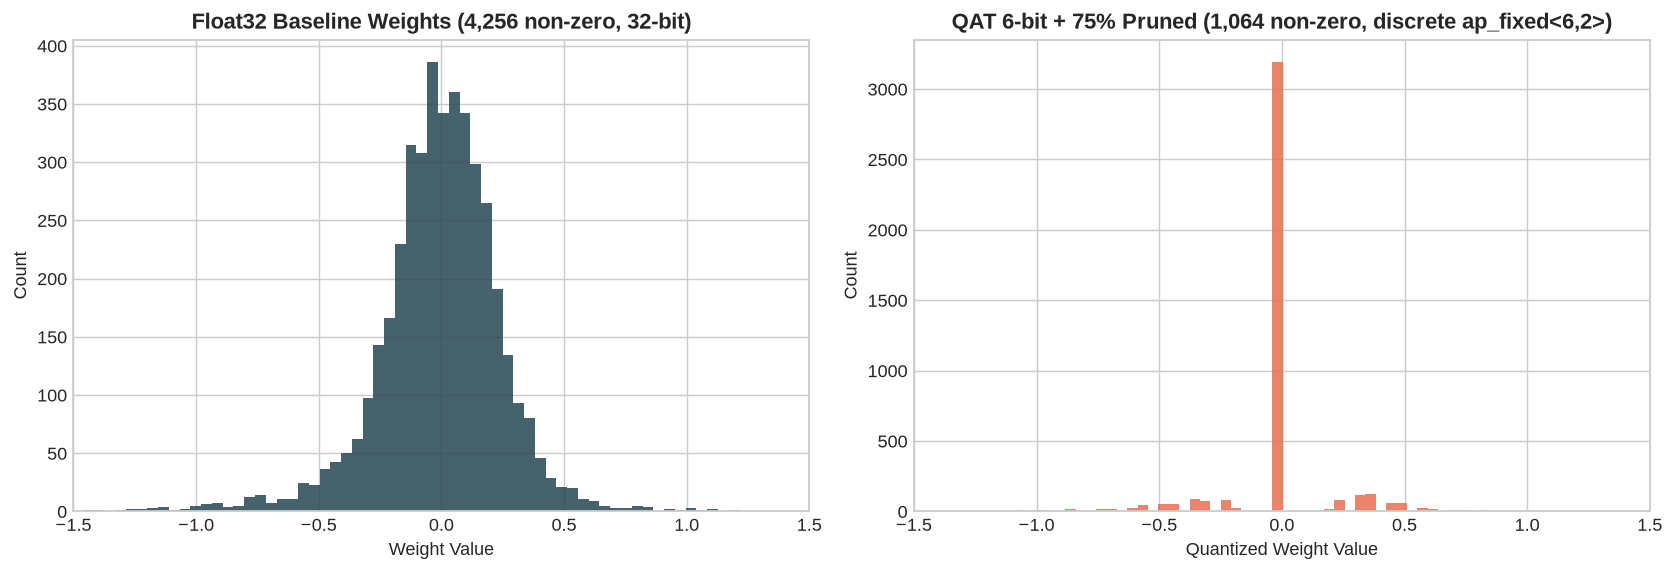

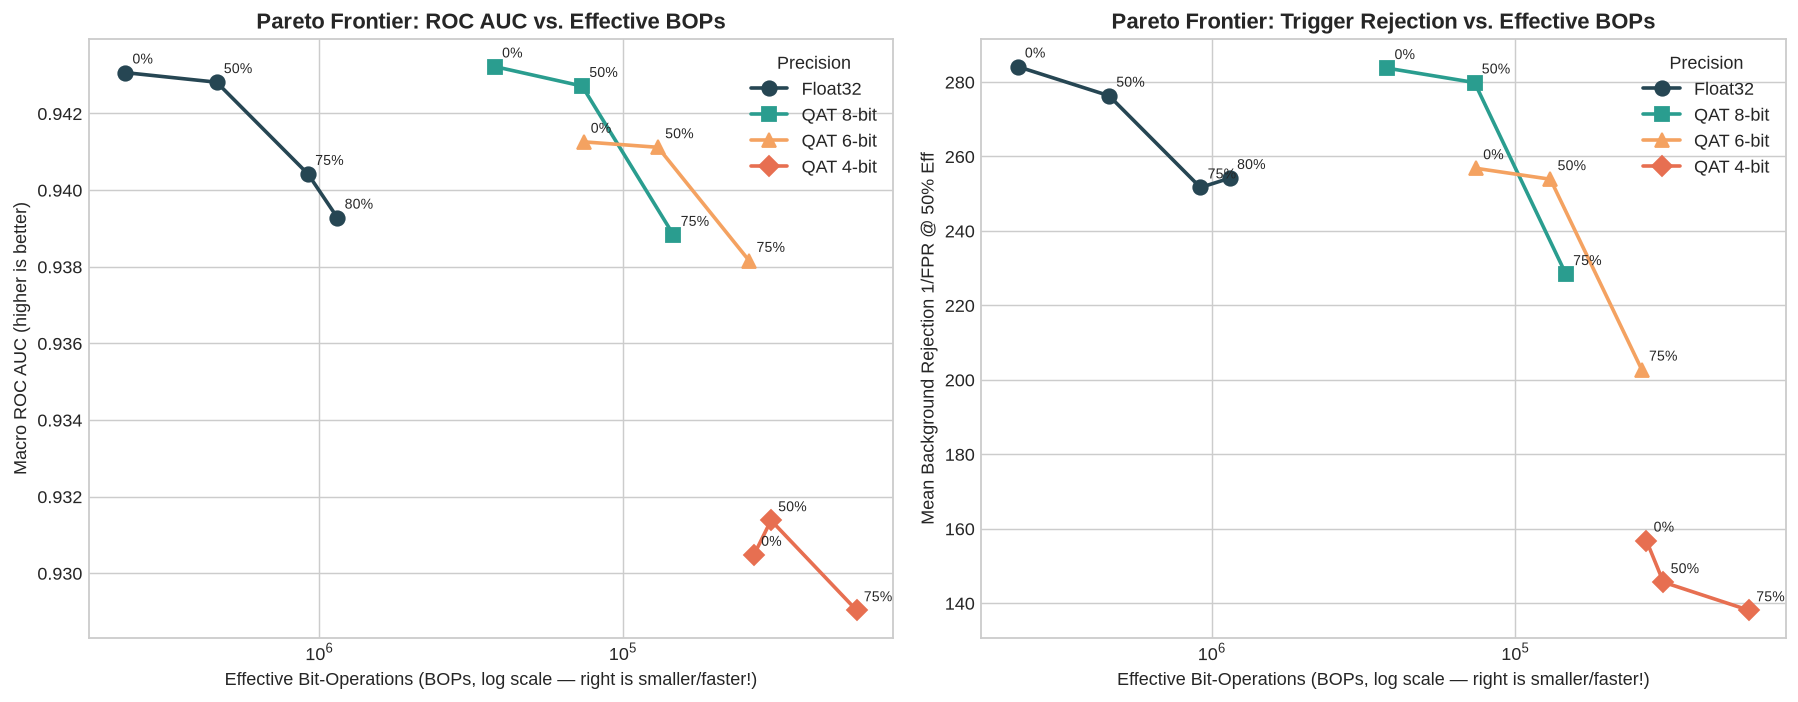

In [5]:
plt.style.use("seaborn-v0_8-whitegrid")

# Figure 1: Weight distribution before vs after QAT + Pruning
fp_weights = np.concatenate([m.weight.detach().cpu().numpy().ravel() for m in float_model.modules() if isinstance(m, nn.Linear)])
q6_exported = saved_models["QAT_6b_p75"].export_to_standard_sequential()
q6_weights = np.concatenate([m.weight.detach().cpu().numpy().ravel() for m in q6_exported.modules() if isinstance(m, nn.Linear)])

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].hist(fp_weights, bins=80, color="#264653", alpha=0.85)
axes[0].set_title(f"Float32 Baseline Weights ({len(fp_weights):,} non-zero, 32-bit)", fontweight="bold")
axes[0].set_xlabel("Weight Value")
axes[0].set_ylabel("Count")
axes[0].set_xlim(-1.5, 1.5)

axes[1].hist(q6_weights, bins=80, color="#e76f51", alpha=0.85)
nz_count = int((q6_weights != 0).sum())
axes[1].set_title(f"QAT 6-bit + 75% Pruned ({nz_count:,} non-zero, discrete ap_fixed<6,2>)", fontweight="bold")
axes[1].set_xlabel("Quantized Weight Value")
axes[1].set_ylabel("Count")
axes[1].set_xlim(-1.5, 1.5)

plt.tight_layout()
plt.savefig(FIG_DIR / "03_weight_distributions_pruning.png", dpi=150)
plt.show()

# Figure 2: Level-1 Pareto Frontier (AUC & Background Rejection vs Effective BOPs)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
bit_palette = {32: "#264653", 8: "#2a9d8f", 6: "#f4a261", 4: "#e76f51"}
bit_markers = {32: "o", 8: "s", 6: "^", 4: "D"}

for bits in [32, 8, 6, 4]:
    sub = sweep_df[sweep_df["weight_bits"] == bits].sort_values("effective_bops")
    label = "Float32" if bits == 32 else f"QAT {bits}-bit"
    axes[0].plot(sub["effective_bops"], sub["macro_auc"], marker=bit_markers[bits],
                 color=bit_palette[bits], linewidth=2, markersize=8, label=label)
    axes[1].plot(sub["effective_bops"], sub["mean_rej_50"], marker=bit_markers[bits],
                 color=bit_palette[bits], linewidth=2, markersize=8, label=label)
    for _, r in sub.iterrows():
        sp_lbl = f"{int(round(r['target_sparsity']*100))}%"
        axes[0].annotate(sp_lbl, (r["effective_bops"], r["macro_auc"]), textcoords="offset points", xytext=(4, 5), fontsize=8)
        axes[1].annotate(sp_lbl, (r["effective_bops"], r["mean_rej_50"]), textcoords="offset points", xytext=(4, 5), fontsize=8)

for ax, ylabel, title in [
    (axes[0], "Macro ROC AUC (higher is better)", "Pareto Frontier: ROC AUC vs. Effective BOPs"),
    (axes[1], "Mean Background Rejection 1/FPR @ 50% Eff", "Pareto Frontier: Trigger Rejection vs. Effective BOPs"),
]:
    ax.set_xscale("log")
    ax.invert_xaxis()  # Moving right = smaller, cheaper FPGA model!
    ax.set_xlabel("Effective Bit-Operations (BOPs, log scale — right is smaller/faster!)")
    ax.set_ylabel(ylabel)
    ax.set_title(title, fontweight="bold")
    ax.legend(title="Precision")

plt.tight_layout()
plt.savefig(FIG_DIR / "03_pareto_frontier.png", dpi=150)
plt.show()
print("Saved Pareto frontier to figures/03_pareto_frontier.png")

## Step 3 Takeaways (What You Just Proved!)
Look at that Pareto plot — **that is the exact story CERN Next Generation Triggers supervisors want to see**:
1. **Pruning 50%–75% of weights** barely touches ROC AUC while cutting FPGA multiply-accumulate circuits in half or by 4×.
2. **Going from 32-bit Float to 8-bit or 6-bit QAT** slashes Effective BOPs by **>96%–99%** while keeping nearly the exact same trigger physics performance!
3. **Why QAT beats PTQ:** At 4-bit precision, naive PTQ loses substantial accuracy, whereas QAT recovers almost all of it by training with fixed-point rounding inside the forward loop.

**Next up → Open `04_hls4ml_hardware_verification.ipynb` to translate our compressed PyTorch model into actual FPGA C++ firmware with `hls4ml` and run bit-accurate verification!**